# rMEDS on the MIMIC-IV OMOP demo

This notebook runs the whole rMEDS pipeline on public data, one step per cell:

**OMOP CDM → mapping pre-flight → MEDS → MEDS-DEV task labels → model → evaluation → results to share**

It uses the PhysioNet [MIMIC-IV demo in the OMOP CDM](https://physionet.org/content/mimic-iv-demo-omop/0.9/)
(open access under the ODbL, 100 patients, an 11 MB download). Every output below is aggregate:
counts, shares and metrics, never patient rows. Keep to the same rule when you run this at your own site.

**You need** R ≥ 4.1 with the Jupyter R kernel ([IRkernel](https://github.com/IRkernel/IRkernel)) and internet access. You don't have to install Jupyter: the
[README](https://github.com/rvandewater/rmeds#try-it-on-public-data) shows how to run it with uv.
The first run downloads the data and builds the pinned Python environment, which takes a few minutes.
After that, sections 1–7 take under a minute and the optional trained model in section 8 about two.

## 0. Set up

`rmeds` runs the Python tools (OMOP_MEDS and MEDS-DEV) from a pinned environment that
reticulate and [uv](https://docs.astral.sh/uv/) build on first use. Tool output goes to log files
in each output folder rather than into the notebook.

In [1]:
# install.packages("pak"); pak::pak("rvandewater/rmeds")
suppressPackageStartupMessages({
  library(rmeds)
  library(dplyr)
})
options(rmeds.verbose = FALSE, width = 110, cli.num_colors = 1,
        repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 120)

setupPythonEnvironment()
info <- pythonEnvironmentInfo()
c(python = info$pythonVersion, info$packages)

python OMOP_MEDS  MEDS-DEV 
   "3.12"   "0.4.0"   "0.1.0"

## 1. Get the data

The work folder must not contain spaces, because MEDS-DEV builds shell commands from paths.
Set the `RMEDS_DEMO_DIR` environment variable to keep the data between sessions; otherwise
it goes to a temporary folder.

In [2]:
work <- Sys.getenv("RMEDS_DEMO_DIR", file.path(tempdir(), "rmeds-mimic-demo"))
dir.create(work, recursive = TRUE, showWarnings = FALSE)

zip <- file.path(work, "mimic-iv-demo-omop-0.9.zip")
if (!file.exists(zip)) {
  download.file("https://physionet.org/content/mimic-iv-demo-omop/get-zip/0.9/", zip,
                mode = "wb", quiet = TRUE)
}
csv <- grep("/1_omop_data_csv/[^/]+\\.csv$", unzip(zip, list = TRUE)$Name, value = TRUE)
invisible(unzip(zip, files = csv, exdir = file.path(work, "omop"), junkpaths = TRUE, overwrite = TRUE))
cat(length(csv), "CDM tables extracted\n")

32 CDM tables extracted


## 2. Look at the OMOP CDM

`omopSource()` wraps a folder of CDM tables as CSV or Parquet. Against a database you would export one first:

```r
omop <- exportCdmToParquet(connectionDetails, cdmDatabaseSchema = "cdm", outputFolder = "work/omop")
```

`openOmopTable()` opens a table lazily with Arrow, so counts like these never load the data into memory.

In [3]:
omop <- omopSource(file.path(work, "omop"))

tables <- c("person", "visit_occurrence", "visit_detail", "condition_occurrence", "drug_exposure",
            "procedure_occurrence", "measurement", "observation", "death", "concept")
data.frame(table = tables,
           rows = vapply(tables, function(t) nrow(openOmopTable(omop, t)), numeric(1)),
           row.names = NULL)

table,rows
<chr>,<dbl>
person,100
visit_occurrence,852
visit_detail,14479
condition_occurrence,16441
drug_exposure,18229
procedure_occurrence,18447
measurement,338550
observation,31390
death,15


## 3. Check the mapping before converting

`runMappingPreflight()` measures, per domain table, how the site's OMOP mapping will shape the MEDS codes:

* **`unmappedShare`:** rows without a standard concept (`concept_id` 0).
* **`notInVocabularyShare`:** concept ids missing from the exported `concept` table. OMOP_MEDS cannot
  turn these into `vocabulary_id//concept_code` codes.
* **`midnightShare`:** event times at exactly 00:00, usually date-only source data and a leakage risk
  for prediction times.
* **`missingUnitShare`:** numeric measurements without a unit.

The report holds shares only, so it can be shared.

In [4]:
preflight <- runMappingPreflight(omop)
preflight

<mappingPreflight>: vocabulary NA, CDM "5.3.1"



                table   rows unmappedShare notInVocabularyShare midnightShare missingUnitShare
 condition_occurrence  16441          0.0%               100.0%          3.2%                -
        drug_exposure  18229          3.0%               100.0%          2.7%                -
 procedure_occurrence  18447          0.0%                99.9%         54.7%                -
          measurement 338550          2.0%               100.0%          3.8%            11.2%
          observation  31390          0.0%               100.0%          8.1%                -
      device_exposure   3855          0.0%               100.0%          6.6%                -
     visit_occurrence    852          0.0%               100.0%          1.5%                -
             specimen    150          0.0%               100.0%          8.7%                -

The demo maps nearly every row to a concept id, yet almost none of those ids are in its `concept` table.
It ships only MIMIC's own local concepts, not the standard OMOP vocabularies. At a real site a high
`notInVocabularyShare` means the vocabulary export is incomplete, and the MEDS codes will not match
any other site's.

## 4. Convert to MEDS

`runOmopToMeds()` runs the OMOP_MEDS ETL in a separate process, so a crash or out-of-memory error never
takes down the R session. MEDS is one row per event: `subject_id`, `time`, `code` and `numeric_value`.

In [5]:
meds <- runOmopToMeds(omop, file.path(work, "meds"),
                      datasetName = "MIMIC_IV_OMOP_DEMO", omopVersion = "5.3", overwrite = TRUE)
summary(meds)
medsData(meds)$schema

474731 events, 8477 distinct codes



Subjects per split: held_out = 10, train = 80, tuning = 10



Schema
subject_id: int64
time: timestamp[us]
code: string
numeric_value: float
text_value: large_string
table_name: large_string
source_block: large_string
unit: int64
visit_occurrence_id: int64

Codes are `vocabulary//code`. Counting events per vocabulary shows what the pre-flight warned about:

In [6]:
byVocabulary <- medsData(meds) |>
  mutate(vocabulary = sub("//.*$", "", code)) |>
  count(vocabulary, name = "events") |>
  collect() |>
  arrange(desc(events)) |>
  mutate(share = round(100 * events / sum(events), 1))
head(byVocabulary, 10)

vocabulary,events,share
<chr>,<int>,<dbl>
mimiciv_meas_chart,258446,54.4
OMOP_measurement,91251,19.2
OMOP_drug_exposure,29462,6.2
mimiciv_meas_chartevents_value,24868,5.2
OMOP_drug_era,15862,3.3
mimiciv_meas_lab_loinc,13452,2.8
mimiciv_meas_wf,12811,2.7
OMOP_condition_occurrence,7666,1.6
OMOP_condition_era,7542,1.6


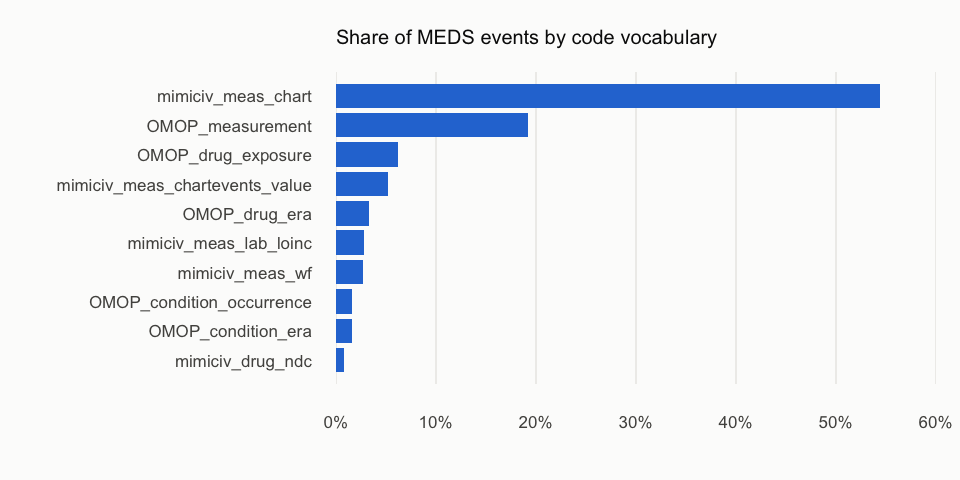

In [7]:
top <- head(byVocabulary, 10)
ink <- "#52514e"; bar <- "#2a78d6"; grid <- "#e6e5e1"
op <- par(mar = c(4, 14, 3, 1), bg = "#fcfcfb", fg = ink, col.axis = ink, col.lab = ink, las = 1)
limit <- 10 * ceiling(max(top$share) / 10)
y <- barplot(rev(top$share), horiz = TRUE, xlim = c(0, limit), col = NA, border = NA, axes = FALSE)
abline(v = seq(0, limit, 10), col = grid)
barplot(rev(top$share), names.arg = rev(top$vocabulary), horiz = TRUE, xlim = c(0, limit),
        col = bar, border = NA, add = TRUE, axes = FALSE, cex.names = 0.85)
axis(1, at = seq(0, limit, 10), labels = paste0(seq(0, limit, 10), "%"), lwd = 0, cex.axis = 0.85)
title(main = "Share of MEDS events by code vocabulary", adj = 0, font.main = 1, col.main = "#0b0b0b", cex.main = 1)
par(op)

Most events carry MIMIC source codes (`mimiciv_*`) or OMOP_MEDS placeholders such as
`OMOP_measurement//measurement_concept_id:…`, used when a concept id is not in the vocabulary.
With the full vocabularies you would see `LOINC`, `SNOMED` and `RxNorm` instead; the Eunomia Synthea
CDM converts to 62% LOINC events. A model trained on standard codes would recognise none of these
features, so check the pre-flight before comparing results across sites.

## 5. Define a task

MEDS-DEV's tasks are [ACES](https://github.com/justin13601/ACES) configurations:

In [8]:
listMedsDevTasks()

[1] "abnormal_lab/blood_chemistry/elevated_creatinine/first_24h"
[2] "abnormal_lab/blood_chemistry/hyponatremia/first_24h"       
[3] "abnormal_lab/blood_chemistry/metabolic_acidosis/first_24h" 
[4] "abnormal_lab/cbc/anemia/first_24h"                         
[5] "abnormal_lab/cbc/leukocytosis/first_24h"                   
[6] "abnormal_lab/cbc/thrombocytopenia/first_24h"               
[7] "abnormal_lab/vital/hypotension/first_24h"                  
[8] "mortality/in_icu/first_24h"

Each task leaves its dataset-specific predicates (what counts as a sodium measurement, an admission, …)
as `???`. A predicates file fills them in using this dataset's codes. Here it uses the demo's
`mimiciv_*` source codes and placeholders; with the standard vocabularies it would use, for example,
`LOINC//2951-2` for serum sodium.

In [9]:
predicates <- file.path(work, "predicates.yaml")
invisible(file.copy(system.file("predicates", "mimic-iv-omop-demo.yaml", package = "rmeds"),
                    predicates, overwrite = TRUE))
cat(readLines(predicates), sep = "\n")

# ACES predicates for the PhysioNet MIMIC-IV OMOP demo (v0.9) after OMOP_MEDS
# 0.4.0. The demo ships only MIMIC's own source concepts, so codes are source
# codes (mimiciv_*) or OMOP_MEDS placeholders for unresolved standard concepts.
predicates:
  hospital_admission:
    code: { regex: '^mimiciv_vis_admission_type//(EW EMER\.|DIRECT EMER\.|URGENT|ELECTIVE|OBSERVATION ADMIT|EU OBSERVATION|DIRECT OBSERVATION|SURGICAL SAME DAY ADMISSION)//start$' }
  hospital_discharge:
    code: { regex: '^mimiciv_vis_admission_type//(EW EMER\.|DIRECT EMER\.|URGENT|ELECTIVE|OBSERVATION ADMIT|EU OBSERVATION|DIRECT OBSERVATION|SURGICAL SAME DAY ADMISSION)//end$' }

  sodium_lab:
    code: "OMOP_measurement//measurement_concept_id:3019550,3019550"
  sodium_chart:
    code: "mimiciv_meas_chart//220645"
  sodium_blood_gas:
    code: "mimiciv_meas_lab_loinc//50824"
  low_sodium_lab:
    code: "OMOP_measurement//measurement_concept_id:3019550,3019550"
    value_max: 135
    value_max_inclusive: False
  low_so

Label the task. Try `"abnormal_lab/blood_chemistry/elevated_creatinine/first_24h"` too: the predicates
file covers creatinine, but the demo has only one positive.

In [10]:
task <- "abnormal_lab/blood_chemistry/hyponatremia/first_24h"

labels <- extractTaskLabels(meds, task, file.path(work, "labels", basename(dirname(task))),
                            dataset = "MIMIC_IV_OMOP_DEMO", predicatesPath = predicates,
                            overwrite = TRUE)
summary(labels)

Task "abnormal_lab/blood_chemistry/hyponatremia/first_24h": 75 labels



Positive: 8 (10.7%)



Labels per split. MEDS-DEV trains on `train`, tunes on `tuning` and evaluates on `held_out`:

In [11]:
labelled <- labelData(labels) |>
  collect() |>
  inner_join(medsSubjectSplits(meds), by = "subject_id")
table(split = labelled$split, positive = labelled$boolean_value)

          positive
split      FALSE TRUE
  held_out     7    0
  train       58    8
  tuning       2    0

## 6. Train, predict and evaluate

`random_predictor` is MEDS-DEV's baseline. It needs no training and checks the plumbing end to end.
With only about 10 held-out patients there may be no positive label to evaluate against, so AUROC can be
undefined and `evaluatePredictions()` warns about it.

In [12]:
run <- runMedsDevModel(meds, labels, model = "random_predictor",
                       outputFolder = file.path(work, "models", "random_predictor"), overwrite = TRUE)
evaluation <- evaluatePredictions(run)
evaluation

Warning message:
“MEDS-Evaluation could not compute "samples_equally_weighted/roc_auc_score" and
"subjects_equally_weighted/roc_auc_score".
ℹ This usually means the evaluated labels hold only one class, common with few held-out subjects.”


,metric,value
,<chr>,<dbl>
1,samples_equally_weighted/binary_accuracy,0.4285714
2,samples_equally_weighted/f1_score,0.0000000
3,samples_equally_weighted/roc_auc_score,NA
4,samples_equally_weighted/average_precision_score,0.0000000
5,samples_equally_weighted/calibration_error,0.5280664
6,subjects_equally_weighted/binary_accuracy,0.4166667
7,subjects_equally_weighted/f1_score,0.0000000
8,subjects_equally_weighted/roc_auc_score,NA
9,subjects_equally_weighted/average_precision_score,0.0000000


## 7. Share the results

`exportResults()` writes the metrics, the pre-flight report and run metadata as small files, suppressing
counts below `minCellCount`. This folder is what a site sends back in a network study.

In [13]:
shared <- exportResults(evaluation, preflight, file.path(work, "share"),
                        minCellCount = 5, databaseId = "mimic_iv_omop_demo")
basename(unlist(shared))
jsonlite::fromJSON(shared[["metadata"]])[c("databaseId", "rmedsVersion", "pythonRequirements", "minCellCount")]

[1] "evaluation.csv" "metadata.json"  "preflight.csv"

$databaseId
[1] "mimic_iv_omop_demo"

$rmedsVersion
[1] "0.0.0.9000"

$pythonRequirements
[1] "OMOP_MEDS==0.4.0" "MEDS-DEV==0.1.0" 

$minCellCount
[1] 5

## 8. Optional: a trained model

`meds_tab/tiny` builds MEDS-TAB tabular features and trains XGBoost. MEDS-DEV installs the model's own
requirements into a temporary environment on first use. Expect about two minutes.

In [14]:
trainMedsTab <- TRUE

if (trainMedsTab) {
  tabRun <- runMedsDevModel(meds, labels, model = "meds_tab/tiny",
                            outputFolder = file.path(work, "models", "meds_tab_tiny"), overwrite = TRUE)
  evaluatePredictions(tabRun)
}

Warning message:
“MEDS-Evaluation could not compute "samples_equally_weighted/roc_auc_score" and
"subjects_equally_weighted/roc_auc_score".
ℹ This usually means the evaluated labels hold only one class, common with few held-out subjects.”


,metric,value
,<chr>,<dbl>
1,samples_equally_weighted/binary_accuracy,1.0000000
2,samples_equally_weighted/f1_score,0.0000000
3,samples_equally_weighted/roc_auc_score,NA
4,samples_equally_weighted/average_precision_score,0.0000000
5,samples_equally_weighted/calibration_error,0.1210781
6,subjects_equally_weighted/binary_accuracy,1.0000000
7,subjects_equally_weighted/f1_score,0.0000000
8,subjects_equally_weighted/roc_auc_score,NA
9,subjects_equally_weighted/average_precision_score,0.0000000


## Next steps

* **Another task:** change `task` in section 5 and re-run from there.
* **Your own CDM:** replace sections 1–2 with `exportCdmToParquet()`, then write a predicates file in the
  codes your MEDS data uses. The vocabulary table in section 4 shows which those are.
* **ICU tasks** such as `mortality/in_icu/first_24h` need ICU stays, which OMOP keeps in `visit_detail`.
  OMOP_MEDS 0.4.0 does not convert that table yet.

See the [README](https://github.com/rvandewater/rmeds#readme) for the design and known limitations.